**Title**: Image Synthesis Using Generative Adversarial Networks (GANs)

**Aim:**

To train a basic Generative Adversarial Network (GAN) using the Fashion-MNIST dataset and PyTorch to generate clothing images and evaluate the generated outputs.

**Software and Libraries Used:**
1. Python
2. Google Colab
3. PyTorch
4. Torchvision
5. Matplotlib
Dataset Used: Fashion-MNIST Dataset.

**Theory**
A Generative Adversarial Network (GAN) is a deep learning model consisting of two neural networks:
1. Generator: Creates fake images using random noise.
2. Discriminator: Determines whether an image is real or fake.
Both networks compete with each other during training. The generator tries to create realistic images, while the discriminator tries to identify fake images.

In [ ]:



from pathlib import Path
import random
import torch
import matplotlib.pyplot as plt

from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid


SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


out = Path("lab_outputs")
out.mkdir(exist_ok=True)

print("Device:", device)
print("PyTorch Version:", torch.__version__)


Device: cpu
PyTorch Version: 2.14.1+cpu


In [ ]:

import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])


data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=transform
)


loader = DataLoader(
    data,
    batch_size=128,
    shuffle=True
)

print("Fashion-MNIST downloaded successfully!")
print("Total images:", len(data))
print("Image shape:", data[0][0].shape)


100%|██████████| 26.4M/26.4M [00:02<00:00, 12.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 202kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.77MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 19.8MB/s]


Fashion-MNIST downloaded successfully!
Total images: 60000
Image shape: torch.Size([1, 28, 28])


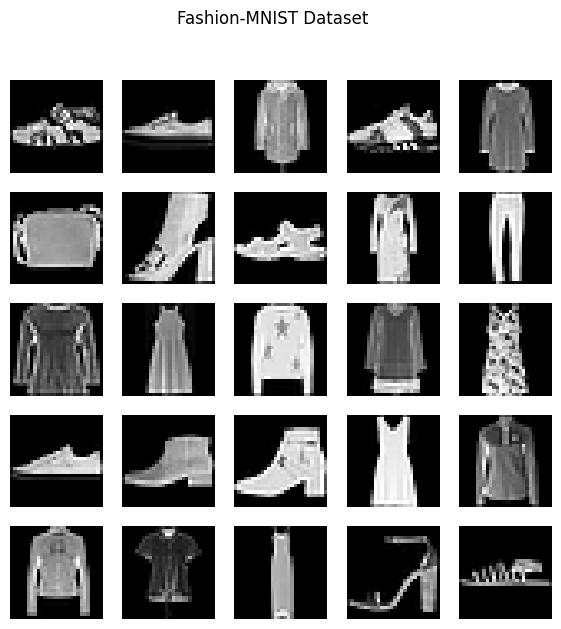

In [ ]:


images, labels = next(iter(loader))

plt.figure(figsize=(7, 7))

for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(
        images[i].squeeze(),
        cmap="gray"
    )
    plt.axis("off")

plt.suptitle("Fashion-MNIST Dataset")
plt.show()


In [ ]:


latent_dim = 64


G = nn.Sequential(
    nn.Linear(latent_dim, 256),
    nn.LeakyReLU(0.2),

    nn.Linear(256, 512),
    nn.LeakyReLU(0.2),

    nn.Linear(512, 784),
    nn.Tanh()
).to(device)

print("Generator Architecture:")
print(G)


Generator Architecture:
Sequential(
  (0): Linear(in_features=64, out_features=256, bias=True)
  (1): LeakyReLU(negative_slope=0.2)
  (2): Linear(in_features=256, out_features=512, bias=True)
  (3): LeakyReLU(negative_slope=0.2)
  (4): Linear(in_features=512, out_features=784, bias=True)
  (5): Tanh()
)


In [ ]:



D = nn.Sequential(
    nn.Flatten(),

    nn.Linear(784, 512),
    nn.LeakyReLU(0.2),

    nn.Linear(512, 256),
    nn.LeakyReLU(0.2),

    nn.Linear(256, 1)
).to(device)

print("Discriminator Architecture:")
print(D)


Discriminator Architecture:
Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=512, bias=True)
  (2): LeakyReLU(negative_slope=0.2)
  (3): Linear(in_features=512, out_features=256, bias=True)
  (4): LeakyReLU(negative_slope=0.2)
  (5): Linear(in_features=256, out_features=1, bias=True)
)


In [ ]:


loss_fn = nn.BCEWithLogitsLoss()


opt_g = torch.optim.Adam(
    G.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
)


opt_d = torch.optim.Adam(
    D.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
)


fixed_z = torch.randn(
    25, latent_dim, device=device
)

print("Loss function and optimizers initialized!")
print("Fixed noise shape:", fixed_z.shape)


Loss function and optimizers initialized!
Fixed noise shape: torch.Size([25, 64])


In [ ]:

with torch.no_grad():
    noise = torch.randn(25, latent_dim).to(device)
    fake_images = G(noise)
    predictions = D(fake_images)

print("Noise shape:", noise.shape)
print("Generator output:", fake_images.shape)
print("Discriminator output:", predictions.shape)


Noise shape: torch.Size([25, 64])
Generator output: torch.Size([25, 784])
Discriminator output: torch.Size([25, 1])


In [ ]:


def generate_grid(epoch):

    with torch.no_grad():
        images = G(fixed_z).cpu().reshape(
            -1, 1, 28, 28
        )

    grid = make_grid((images + 1) / 2, nrow=5)

    plt.figure(figsize=(5, 5))
    plt.imshow(grid.permute(1, 2, 0))
    plt.title(f"Epoch {epoch}")
    plt.axis("off")

    plt.savefig(
        out / f"gan_epoch_{epoch:02d}.png",
        bbox_inches="tight"
    )

    plt.show()



def train_batch(real):

    n = real.size(0)


    fake = G(
        torch.randn(n, latent_dim, device=device)
    )


    real_logits = D(real)
    fake_logits = D(fake.detach())

    d_loss = (
        loss_fn(
            real_logits,
            torch.ones_like(real_logits)
        )
        + loss_fn(
            fake_logits,
            torch.zeros_like(fake_logits)
        )
    ) / 2

    opt_d.zero_grad()
    d_loss.backward()
    opt_d.step()


    D.requires_grad_(False)

    opt_g.zero_grad()

    logits = D(fake)

    g_loss = loss_fn(
        logits,
        torch.ones_like(logits)
    )

    g_loss.backward()
    opt_g.step()

    D.requires_grad_(True)

    return d_loss.item(), g_loss.item()


print("GAN training functions created successfully!")


GAN training functions created successfully!


01 D=0.342 G=1.843


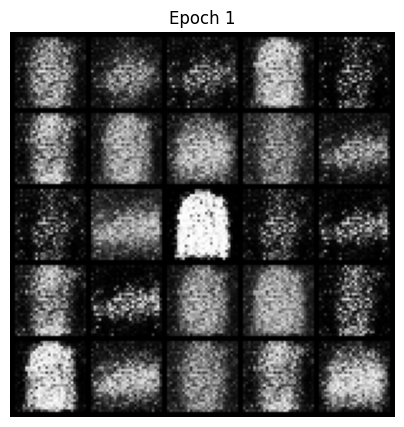

02 D=0.338 G=2.583
03 D=0.350 G=2.362
04 D=0.375 G=2.257
05 D=0.410 G=2.042


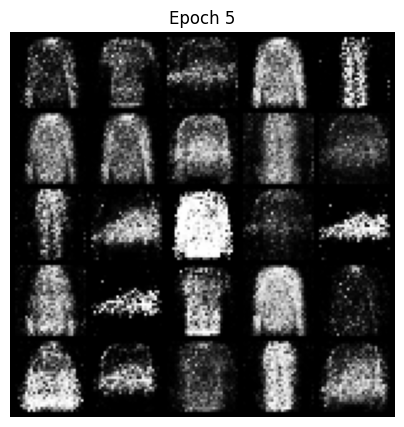

06 D=0.429 G=1.928
07 D=0.436 G=1.898
08 D=0.446 G=1.857
09 D=0.458 G=1.768
10 D=0.460 G=1.779


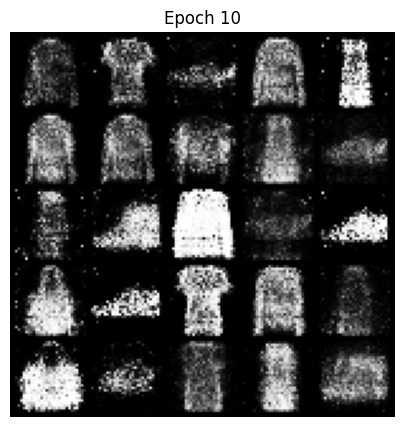

GAN training completed!


In [ ]:


history = []

for epoch in range(1, 11):

    losses = [
        train_batch(real.to(device))
        for real, _ in loader
    ]

    avg_d, avg_g = [
        sum(values) / len(losses)
        for values in zip(*losses)
    ]

    history.append((avg_d, avg_g))

    print(
        f"{epoch:02d} "
        f"D={avg_d:.3f} "
        f"G={avg_g:.3f}"
    )

    if epoch in (1, 5, 10):
        generate_grid(epoch)

print("GAN training completed!")


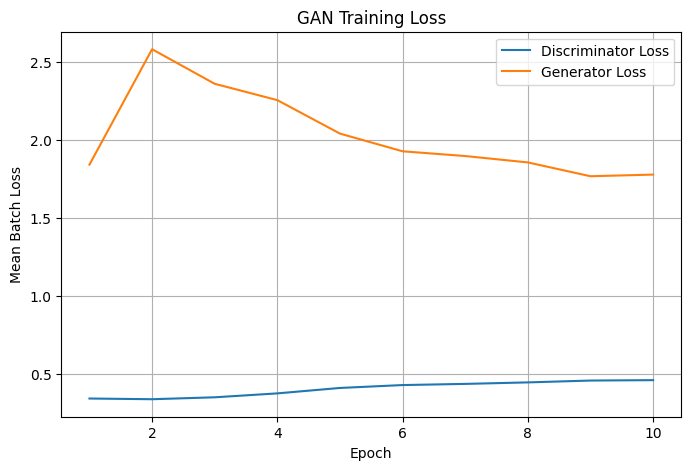

In [ ]:



plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    [d for d, g in history],
    label="Discriminator Loss"
)

plt.plot(
    range(1, 11),
    [g for d, g in history],
    label="Generator Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Batch Loss")
plt.title("GAN Training Loss")

plt.legend()
plt.grid()

plt.savefig(
    out / "gan_losses.png",
    bbox_inches="tight"
)

plt.show()


In [ ]:



torch.save(
    G.state_dict(),
    out / "fashion_generator.pt"
)

print("Generator model saved successfully!")


Generator model saved successfully!
